# Biblio

In [65]:
import os
import sys
sys.path.append(os.path.abspath(".."))
sys.path.append(os.path.abspath("."))

import os
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import importlib
from utils_files import utils_credit
from utils_files import utils_ai4i
from utils_files import utils_partie3
from utils_files import utils_partie5
import numpy as np

from utils_files import utils_credit
importlib.reload(utils_credit)


<module 'utils_files.utils_credit' from 'c:\\Users\\DELL\\Desktop\\M2 France\\ML\\TPs\\TP-Anomalie-ML\\utils_files\\utils_credit.py'>

In [66]:
# Import de nos fonctions utils
sys.path.append(os.path.abspath("."))
from utils_files import utils_credit

print("Pandas version :", pd.__version__)
print("Numpy version  :", np.__version__)

Pandas version : 3.0.6
Numpy version  : 2.4.6


# 1. Préparer Credit Card

## a. Examiner les données

- Types des colonnes
- Recherche de valeurs manquantes
- Détection et suppression des doublons
- Proportion de fraudes
- Gestion de Time et découpage stratifié (60% Train / 20% Val / 20% Test)

### Examen initial (types, valeurs manquantes, doublons)

In [46]:
# Chargement brut et examen initial (dimensions, valeurs manquantes, doublons, types)
df_raw = utils_credit.examiner_donnees_brutes("../data/creditcard.csv")

=== Examen initial du jeu de données brut ===
Dimensions               : 284807 lignes, 31 colonnes
Valeurs manquantes       : 0
Nombre de doublons       : 1081 (0.38%)
Types de colonnes        : {'float64': 30, 'int64': 1}


### Nettoyage des doublons et calcul du déséquilibre

=== Distribution des classes ===
Transactions normales (0) : 283253 (99.833%)
Fraudes (1)               : 473 (0.167%)
Ratio de déséquilibre     : 1 fraude pour 599 transactions normales


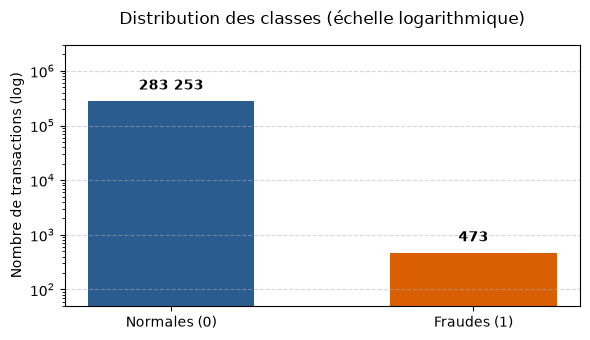

In [47]:
# Nettoyage des doublons et calcul des proportions de classe
df = utils_credit.load_clean_data("../data/creditcard.csv")
utils_credit.afficher_desequilibre_classes(df)

# Graphique du déséquilibre de classe
utils_credit.tracer_distribution_classes(df)

### Découpage stratifié (60% Train / 20% Val / 20% Test)

In [48]:
# Découpage stratifié avec exclusion de 'Time' et 'Class' de X
X_train, X_val, X_test, y_train, y_val, y_test = utils_credit.split_data(df, random_state=42)

utils_credit.verifier_decoupage(y_train, y_val, y_test)

,Partition,Total transactions,Nb fraudes,Taux de fraude
0,Train (60%),170 235,284,0.167%
1,Val (20%),56 745,94,0.166%
2,Test (20%),56 746,95,0.167%


### Analyse de Time et limites du découpage aléatoire

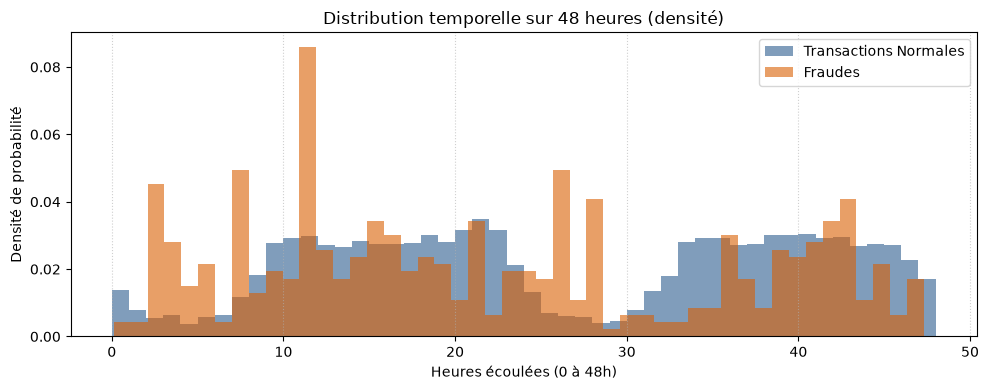

In [49]:
# Visualisation de la distribution temporelle des transactions
utils_credit.tracer_distribution_temporelle(df)

#### Limites du découpage aléatoire par rapport à la variable Time :

1. **Fuite temporelle (Data leakage / interpolation) :**
   Un découpage aléatoire mélange les données du jour 1 et du jour 2. Le modèle risque donc d'apprendre sur des transactions du futur pour prédire des fraudes du passé, ce qui est impossible dans la réalité.

2. **Dérive de concept (Concept Drift) :**
   Les comportements légitimes suivent des cycles jour/nuit (creux la nuit, pics le jour), alors que les méthodes des fraudeurs s'adaptent et évoluent en permanence dans le temps.

3. **Inadéquation avec la production réelle :**
   En conditions réelles dans une banque, on s'entraîne toujours sur le passé ($t < T$) pour prédire sur le futur ($t \ge T$). Un découpage chronologique serait donc indispensable en pratique. Nous écartons `Time` des prédicteurs pour cette comparaison afin d'éviter qu'il n'apprenne des corrélations temporelles factices.


## b. Étude des échelles des variables et prétraitement

### Observer les échelles (Amount vs V1 à V28)

In [50]:
# Comparaison des échelles entre Amount et les composantes ACP V1..V28
utils_credit.analyser_echelles_variables(X_train)

=== Échelle de la variable 'Amount' (Train) ===
Médiane : 22.00 € | Moyenne : 88.30 € | Écart-type : 243.92 €
Min     : 0.00 € | Max     : 18910.00 € | IQR (Q3 - Q1) : 72.04 €

=== Échelle des variables issues de l'ACP (V1 à V28) (Train) ===
Moyenne globale des V_i     : 0.0005 (centrées en 0)
Écart-type moyen des V_i    : 0.9702 (unitaires)
Étendue globale (min / max) : [-73.22 ; 38.12]


### Visualiser la distribution de Amount

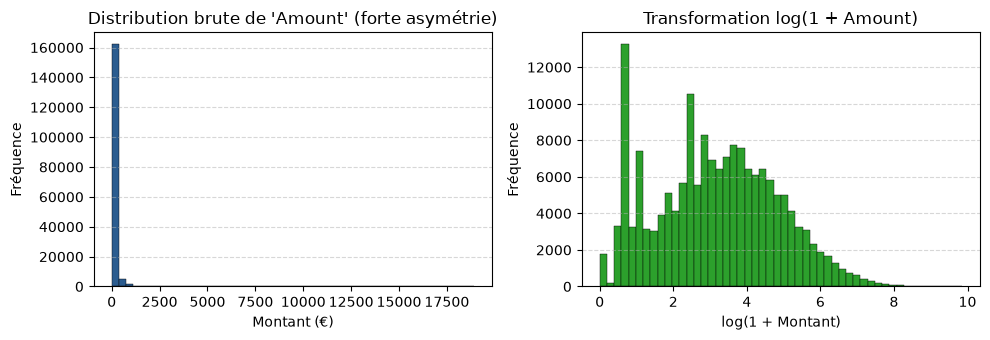

In [51]:
# Distribution brute de Amount vs transformation log(1 + Amount)
utils_credit.tracer_distribution_montant(X_train)

#### Justification du prétraitement par famille d'algorithmes :

1. **Méthodes fondées sur les distances (LOF, k-NN dans SMOTE) :**
   - **Forte sensibilité à l'échelle :** La distance euclidienne calcule la somme des écarts au carré $\sum (x_i - y_i)^2$. Comme `Amount` varie entre 0 et 18 910 € alors que $V_1 \dots V_{28}$ varient entre -5 et +5, la variable `Amount` écraserait toutes les autres composantes.
   - **Pourquoi `RobustScaler` plutôt que `StandardScaler` ?** `StandardScaler` utilise la moyenne et l'écart-type, qui sont très déformés par les montants extrêmes (outliers). `RobustScaler` repose sur la **médiane** et l'**écart interquartile (IQR)**, ce qui le rend résilient aux montants atypiques.

2. **Modèles linéaires (Régression Logistique) :**
   - La régularisation ($L_2$) applique une pénalité uniforme sur les coefficients. Sans mise à l'échelle, le coefficient de `Amount` serait artificiellement écrasé par rapport à ceux des $V_i$.

3. **Modèles arborescents (Arbre de décision, Isolation Forest) :**
   - Ils sont **invariants aux changements d'échelle monotones** car leurs découpages univariés ($X_j \le \theta$) ne dépendent que du rang/ordre des valeurs. La mise à l'échelle ne change pas leurs décisions mais uniformise le pipeline.

4. **Variables $V_1$ à $V_{28}$ :**
   - Issues d'une ACP (PCA), elles sont déjà centrées en 0 et réduites. Étant anonymisées pour préserver le secret bancaire, toute interprétation métier causale est impossible ; nous les conservons donc sans transformation.


### Appliquer la mise à l'échelle (scale_amount) sur Train uniquement

In [52]:
# Mise à l'échelle robuste ajustée strictement sur Train
X_train_s, X_val_s, X_test_s = utils_credit.scale_amount(X_train, X_val, X_test)
utils_credit.verifier_mise_a_echelle(X_train_s)

=== Vérification de 'Amount' après RobustScaler (Train) ===
Médiane (doit être 0.0)  : 0.0000
Q1 (-0.227 typique)      : -0.2275
Q3 (+0.773 typique)      : 0.7725
IQR normalisé (Q3 - Q1)  : 1.0000 (égal à 1.0)
Min / Max                : [-0.305 ; 262.206]


### Boxplot Avant vs Après RobustScaler

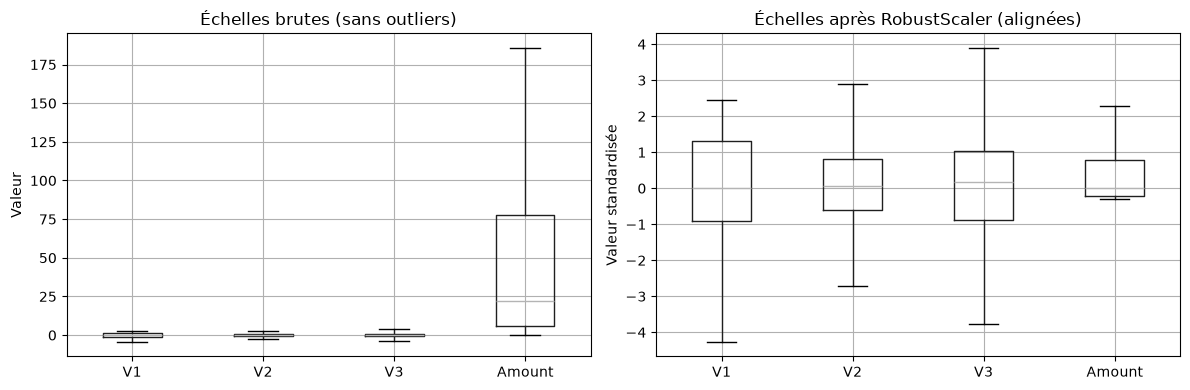

In [53]:
utils_credit.tracer_boxplots_comparatifs(X_train, X_train_s)

# 2. Comparer et prendre une décision

## a. Comparaison des modèles supervisés (Arbre de décision et Régression Logistique)


Pour chaque modèle, nous étudions 3 variantes :
1. Sans correction du déséquilibre
2. Avec pondération des classes (`class_weight='balanced'`)
3. Avec rééchantillonnage **SMOTE** (justifié par la création de données synthétiques fiables grâce à notre mise à l'échelle préalable).

Le rééchantillonnage est appliqué **exclusivement sur les données d'apprentissage** (`X_train_s`, `y_train`).

### **Justification du choix de la méthode de rééchantillonnage (SMOTE) :**

Parmi les méthodes proposées par le sujet, nous avons retenu **SMOTE** pour les raisons suivantes :
- **RandomUnderSampler** élimine aléatoirement plus de 99% des transactions normales, ce qui détruit une quantité massive d'informations représentatives.
- **RandomOverSampler** duplique à l'identique les mêmes fraudes existantes, favorisant le surapprentissage (*overfitting*).
- **Tomek Links** ne fait qu'un nettoyage frontière sans corriger le ratio extrême de 1 fraude pour 600 normales.
- **SMOTE (Synthetic Minority Over-sampling Technique)** génère de nouvelles fraudes synthétiques intelligentes par interpolation entre voisins réels dans l'espace des descripteurs. Notre mise à l'échelle préalable (`RobustScaler`) garantit que le calcul des plus proches voisins (k-NN) dans SMOTE est mathématiquement fiable et équilibré.

> **Règle méthodologique :** SMOTE est ajusté et appliqué **exclusivement sur les données d'apprentissage** (`X_train_s`). Les partitions de validation et de test restent dans leur distribution déséquilibrée réelle.

### Créer le jeu rééchantillonné avec SMOTE

In [54]:
# Application de SMOTE uniquement sur le jeu d'entraînement
X_train_smote, y_train_smote = utils_credit.appliquer_smote(X_train_s, y_train)

Effectifs Train initial : 170235 dont 284 fraudes
Effectifs Train SMOTE   : 339902 dont 169951 fraudes


### Évaluer la Régression Logistique (3 variantes)

Régression Logistique : Comparaison des 3 variantes


,Modèle,AP (Validation),AUC-ROC
0,LR (Sans correction),0.6968,0.9697
1,LR (Pondération classes),0.6927,0.9713
2,LR (SMOTE),0.6905,0.9700


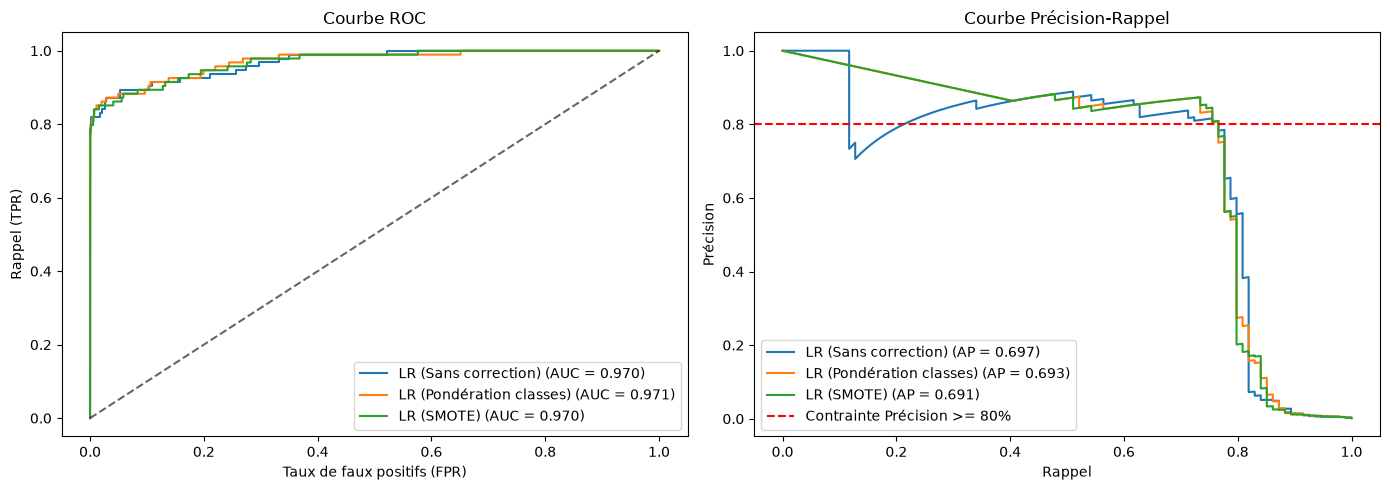

In [55]:
# Évaluation et comparaison des 3 variantes de Régression Logistique
df_res_lr, scores_lr_dict, modeles_lr = utils_credit.evaluer_variantes_supervisees(
    X_train_s, y_train, X_train_smote, y_train_smote, X_val_s, y_val, type_modele="lr"
)

### Évaluer l'Arbre de Décision (3 variantes)

Arbre de Décision : Comparaison des 3 variantes


,Modèle,AP (Validation),AUC-ROC
0,Arbre (Sans correction),0.6684,0.8563
1,Arbre (Pondération classes),0.4343,0.8878
2,Arbre (SMOTE),0.3420,0.9628


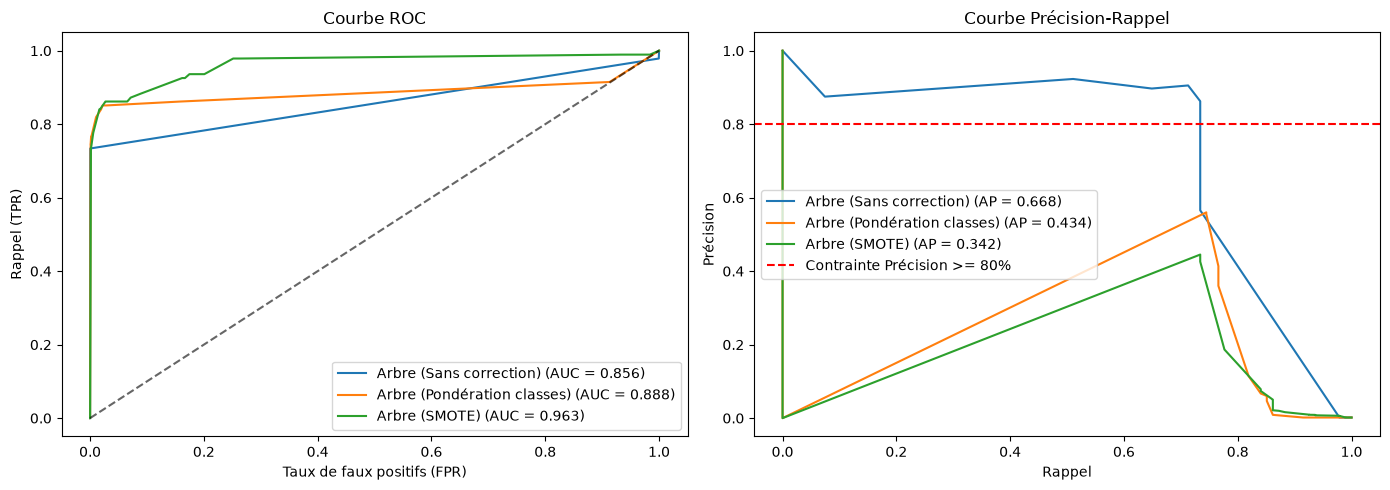

In [56]:
# Évaluation et comparaison des 3 variantes de l'Arbre de Décision
df_res_dt, scores_dt_dict, modeles_dt = utils_credit.evaluer_variantes_supervisees(
    X_train_s, y_train, X_train_smote, y_train_smote, X_val_s, y_val, type_modele="arbre"
)

### Comparaison des 6 variantes

Classement des modèles selon : AP (Validation)


,Rang,Modèle,AP (Validation),AUC-ROC
0,1,LR (Sans correction),0.6968,0.9697
1,2,LR (Pondération classes),0.6927,0.9713
2,3,LR (SMOTE),0.6905,0.9700
3,4,Arbre (Sans correction),0.6684,0.8563
4,5,Arbre (Pondération classes),0.4343,0.8878
5,6,Arbre (SMOTE),0.3420,0.9628


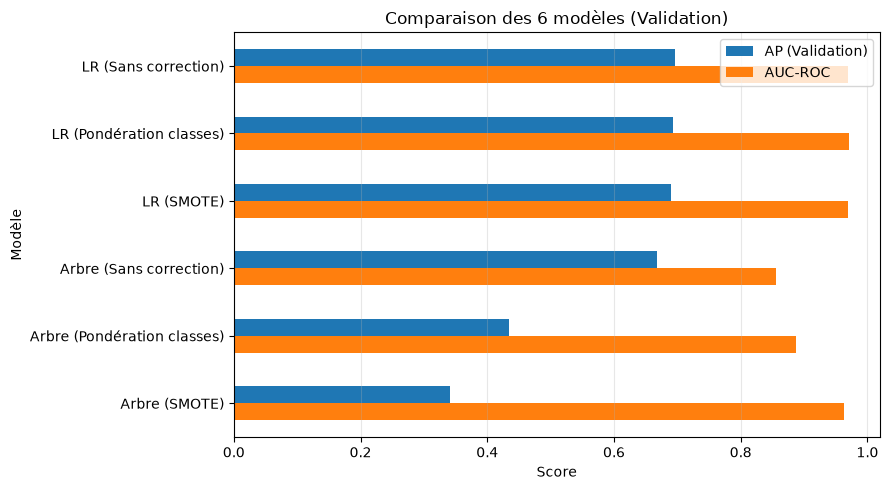


Meilleure variante par famille :
  Arbre -> Sans correction (AP (Validation) = 0.6684)
  LR -> Sans correction (AP (Validation) = 0.6968)

Meilleur modèle global : LR (Sans correction)


In [57]:
df_comparaison, meilleur_modele = utils_credit.comparer_modeles(df_res_lr, df_res_dt)

## b. Sélection des hyperparamètres (6 configurations par modèle)

Conformément aux consignes, nous testons au maximum 6 configurations par modèle :
- **Régression Logistique :** 2 valeurs de régularisation ($C=0.01$ et $C=1.0$) pour chacune des 3 variantes de déséquilibre (Sans correction, Balanced, SMOTE).
- **Arbre de décision :** 2 profondeurs maximales (`max_depth=5` et `max_depth=10`) pour chacune des 3 variantes. Des profondeurs limitées permettent de régulariser l'arbre et d'éviter le surapprentissage.

### Tester les 6 configurations de la Régression Logistique

Régression Logistique : Évaluation des 6 configurations


,C,Variante,AP,AUC-ROC,Contrainte (>=80%),Seuil,Précision,Rappel,F1-score,Balanced Accuracy,FP (Fausses alertes),FN (Fraudes manquées),TP (Fraudes détectées),TN (Normales correctes)
1,1.00,Sans correction,0.6968,0.9697,Atteint,0.075610,0.8090,0.7660,0.7869,0.8828,17,22,72,56634
3,1.00,Pondération,0.6927,0.9713,Atteint,0.999994,0.8090,0.7660,0.7869,0.8828,17,22,72,56634
5,1.00,SMOTE,0.6905,0.9700,Atteint,0.999998,0.8090,0.7660,0.7869,0.8828,17,22,72,56634
0,0.01,Sans correction,0.6857,0.9750,Atteint,0.083164,0.8000,0.7234,0.7598,0.8616,17,26,68,56634
4,0.01,SMOTE,0.6784,0.9698,Atteint,0.999996,0.8276,0.7660,0.7956,0.8828,15,22,72,56636
2,0.01,Pondération,0.6696,0.9711,Atteint,0.999991,0.8161,0.7553,0.7845,0.8775,16,23,71,56635


MEILLEUR MODÈLE LR : C=0.01, SMOTE
   Respecte contrainte (Précision >= 80%)
   Alertes      : 87
   AP           : 0.6784
   AUC-ROC      : 0.9698
   Seuil optimal: 1.0000
   Précision    : 0.8276 (contrainte >= 0.80)
   Rappel       : 0.7660
   F1-score     : 0.7956


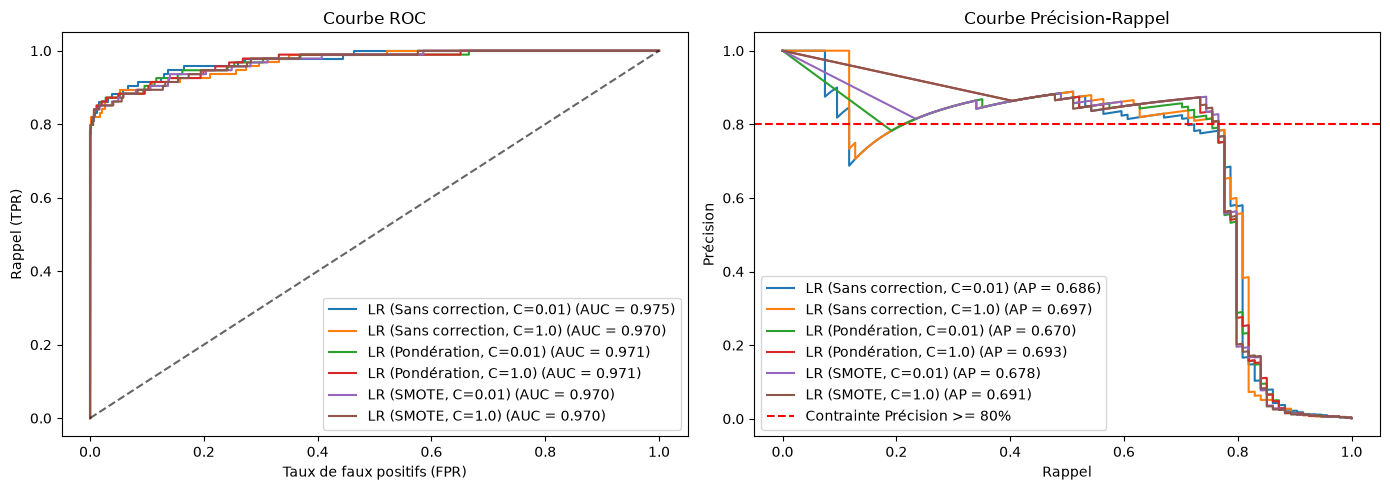

In [58]:
# Évaluation des 6 configurations de Régression Logistique (C in {0.1, 1.0} x 3 variantes)
df_eval_lr, scores_6_lr = utils_credit.evaluer_grille_lr(
    X_train_s, y_train, X_train_smote, y_train_smote, X_val_s, y_val
)

# Tracé des courbes ROC et Précision-Rappel des 6 configurations
utils_credit.tracer_courbes_roc_pr(y_val, scores_6_lr)


### Tester les 6 configurations de l'Arbre de Décision

Arbre de Décision : Évaluation des 6 configurations


,Profondeur,Variante,AP,AUC-ROC,Contrainte (>=80%),Seuil,Précision,Rappel,F1-score,Balanced Accuracy,FP (Fausses alertes),FN (Fraudes manquées),TP (Fraudes détectées),TN (Normales correctes)
0,5,Sans correction,0.6684,0.8563,Atteint,0.050000,0.8625,0.7340,0.7931,0.8669,11,25,69,56640
1,10,Sans correction,0.5929,0.8321,Atteint,1.000000,0.8750,0.6702,0.7590,0.8350,9,31,63,56642
3,10,Pondération,0.4369,0.8822,Non atteint,0.999104,0.5812,0.7234,0.6445,0.8613,49,26,68,56602
2,5,Pondération,0.4343,0.8878,Non atteint,0.998761,0.5600,0.7447,0.6393,0.8719,55,24,70,56596
5,10,SMOTE,0.3609,0.8327,Non atteint,0.999371,0.4928,0.7234,0.5862,0.8611,70,26,68,56581
4,5,SMOTE,0.3420,0.9628,Non atteint,0.998291,0.4452,0.7340,0.5542,0.8663,86,25,69,56565


MEILLEUR MODÈLE ARBRE : Profondeur=5, Sans correction
   Respecte contrainte (Précision >= 80%)
   Alertes      : 80
   AP           : 0.6684
   AUC-ROC      : 0.8563
   Seuil optimal: 0.0500
   Précision    : 0.8625 (contrainte >= 0.80)
   Rappel       : 0.7340
   F1-score     : 0.7931


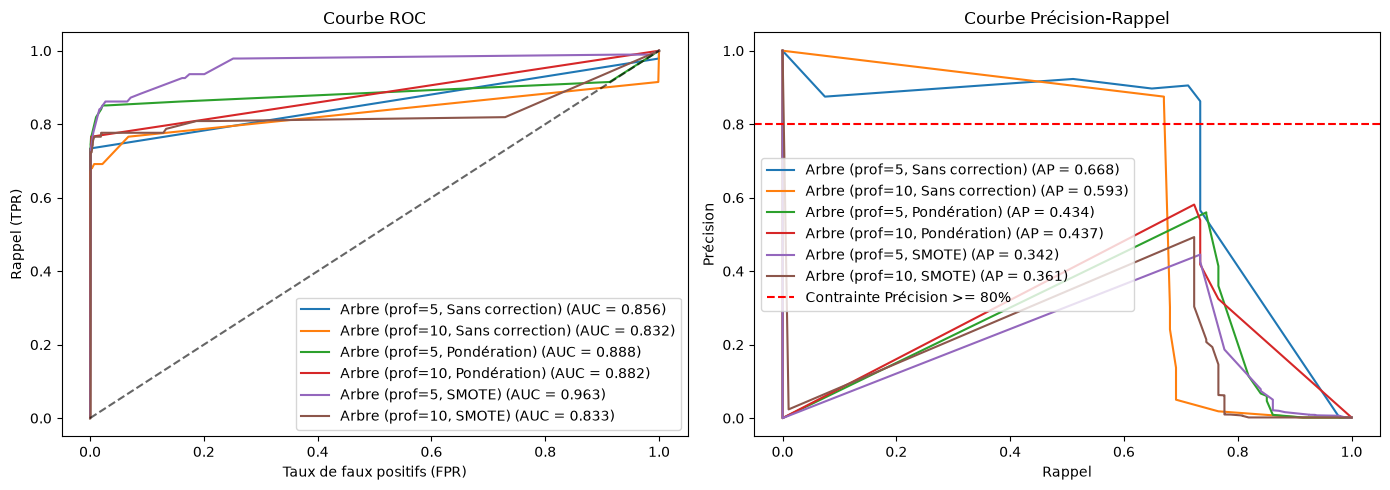

In [59]:
# Évaluation des 6 configurations de l'Arbre de Décision (max_depth in {3, 5} x 3 variantes)
df_eval_dt, scores_6_dt = utils_credit.evaluer_grille_arbre(
    X_train_s, y_train, X_train_smote, y_train_smote, X_val_s, y_val
)

# Tracé des courbes ROC et Précision-Rappel des 6 configurations de l'Arbre
utils_credit.tracer_courbes_roc_pr(y_val, scores_6_dt)


### Justification des configurations testées et sélection du meilleur modèle :

#### 1. Justification des hyperparamètres choisis (6 configurations par modèle) :

   - **Régression Logistique :** Nous explorons le paramètre de régularisation 
     $C \in \{0.01, 1.0\}$ sur les 3 variantes de déséquilibre ($2 \times 3 = 6$ configs).
     • C=0.01 : régularisation FORTE → coefficients stables mais potentiellement biaisés
     • C=1.0 : régularisation MODÉRÉE (défaut) → meilleur compromis flexibilité/stabilité
     
   - **Arbre de Décision :** Nous testons deux profondeurs $\text{max\_depth} \in \{5, 10\}$ 
     sur les 3 variantes ($2 \times 3 = 6$ configs). Pour 284k lignes :
     • depth=5 : très conservateur, risque d'underfitting
     • depth=10 : modéré, capte la complexité sans surapprendre

2. **Sélection du meilleur modèle :**
   - Parmi les modèles respectant Précision ≥ 80%, on prend celui avec le meilleur AP
   - Si aucun ne respecte la contrainte, on signale "objectif non atteint" 
     et on prend le meilleur compromis observé

#### 2. Tableau récapitulatif 

In [60]:
# Après evaluer_grille_lr() et evaluer_grille_arbre()
modele_final, type_modele = utils_credit.recapitulatif_section_2b(df_eval_lr, df_eval_dt)

RÉCAPITULATIF SECTION 2.b - COMPARAISON DES 12 CONFIGURATIONS

TABLEAU COMPARATIF FINAL (Meilleur de chaque famille)


,Modèle,Config,AP,AUC-ROC,Seuil,Précision,Rappel,F1-score
0,Régression Logistique,"C=0.01, SMOTE",0.6784,0.9698,0.999996,0.8276,0.766,0.7956
1,Arbre de Décision,"depth=5, Sans correction",0.6684,0.8563,0.050000,0.8625,0.734,0.7931


GAGNANT FINAL : Régression Logistique (Rappel=0.7660, Précision=0.8276, AP=0.6784)


## c. Modèles non supervisés : Isolation Forest et Local Outlier Factor (LOF)

Nous entraînons ces deux modèles de façon purement non supervisée (sans utiliser les étiquettes y_train et sans rééchantillonnage).

Pour LOF, nous utilisons novelty=True : le modèle est ajusté sur un sous-échantillon aléatoire de 30 000 transactions du Train (le coût de LOF croît en $O(N^2)$), puis sert uniquement à scorer les jeux de Validation et de Test. Isolation Forest, lui, est ajusté sur l'ensemble du Train. Les observations d'entraînement ne sont pas réévaluées en mode novelty.

Conformément au protocole, nous harmonisons les scores en inversant leur signe (-score_samples) pour qu'une valeur plus élevée indique systématiquement une observation plus suspecte.

### Entraînement et Évaluation complète d'Isolation Forest et LOF

In [ ]:
importlib.reload(utils_credit)

# IF ajusté sur tout le Train ; LOF (novelty=True) ajusté sur un sous-échantillon de 30 000 transactions ; seuils calibrés sur la Validation
idx_lof = np.random.default_rng(42).choice(len(X_train_s), size=30000, replace=False)
X_train_lof = np.asarray(X_train_s)[idx_lof]

# Le nombre de fraudes présentes dans ce sous-échantillon est affiché à titre de contrôle : il n'intervient ni dans le tirage, ni dans l'ajustement.
print("Fraudes dans le sous-échantillon LOF :", int(np.asarray(y_train)[idx_lof].sum()))

df_eval_non_sup, scores_non_sup_dict, detecteurs = utils_credit.entrainer_modeles_non_supervises(
    X_train_s, X_val_s, y_val, X_train_lof=X_train_lof, random_state=42, min_precision=0.80
)

Fraudes dans le sous-échantillon LOF : 42
--- Entraînement des détecteurs non supervisés (sans étiquettes) ---
Entraînement de Isolation Forest (6 configurations, 170235 transactions)...
Entraînement de Local Outlier Factor (LOF) (6 configurations, 30000 transactions)...
Grille des configurations (AP sur la Validation, sélection des hyperparamètres)


,Modèle,n_estimators,max_samples,AP (Validation),n_neighbors
0,Isolation Forest,100.0,256.0,0.0861,NaN
1,Isolation Forest,100.0,1024.0,0.1516,NaN
2,Isolation Forest,100.0,2048.0,0.1422,NaN
3,Isolation Forest,200.0,256.0,0.0904,NaN
4,Isolation Forest,200.0,1024.0,0.1463,NaN
5,Isolation Forest,200.0,2048.0,0.1473,NaN
6,Local Outlier Factor (LOF),NaN,NaN,0.0027,10.0
7,Local Outlier Factor (LOF),NaN,NaN,0.0116,20.0
8,Local Outlier Factor (LOF),NaN,NaN,0.3178,50.0
9,Local Outlier Factor (LOF),NaN,NaN,0.4060,100.0



Détecteurs non supervisés : Résultats sur la Validation (meilleure configuration par modèle)


,Modèle,Hyperparamètres,AP,AUC-ROC,Contrainte (>=80%),Seuil,Précision,Rappel,F1-score,Balanced Accuracy,FP (Fausses alertes),FN (Fraudes manquées),TP (Fraudes détectées),TN (Normales correctes)
0,Isolation Forest,"n_estimators=100, max_samples=1024",0.1516,0.9452,Non atteint,0.633711,0.2329,0.3617,0.2833,0.6799,112,60,34,56539
1,Local Outlier Factor (LOF),n_neighbors=100,0.4060,0.9470,Non atteint,2.674428,0.5278,0.6064,0.5644,0.8027,51,37,57,56600


MEILLEUR MODÈLE NON SUPERVISÉ : Local Outlier Factor (LOF)
   Objectif non atteint (aucune config avec Précision >= 80%)
   Alertes      : 108
   AP           : 0.4060
   AUC-ROC      : 0.9470
   Seuil optimal: 2.6744
   Précision    : 0.5278
   Rappel       : 0.6064
   F1-score     : 0.5644



Détecteurs non supervisés : Résultats sur la Validation


,Modèle,AP,AUC-ROC,Contrainte (>=80%),Seuil,Précision,Rappel,F1-score,Balanced Accuracy,FP (Fausses alertes),FN (Fraudes manquées)
0,Isolation Forest,0.1516,0.9452,Non atteint,0.633711,0.2329,0.3617,0.2833,0.6799,112,60
1,Local Outlier Factor (LOF),0.4060,0.9470,Non atteint,2.674428,0.5278,0.6064,0.5644,0.8027,51,37


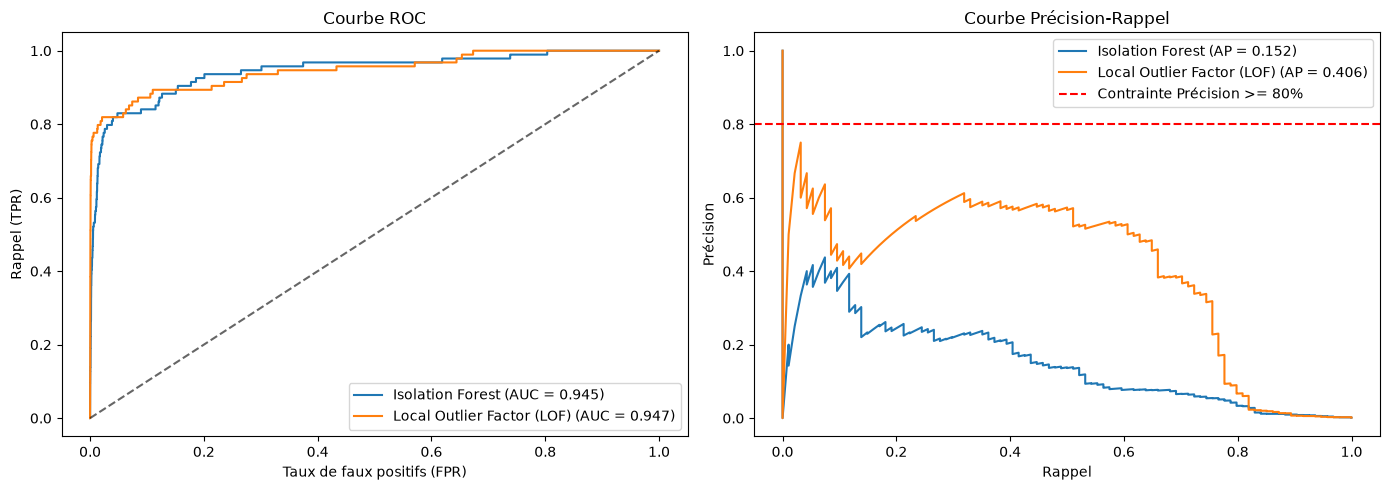

In [68]:
# Tableau récapitulatif
colonnes_ordre = [
    "Modèle",
    "AP",
    "AUC-ROC",
    "Contrainte (>=80%)",
    "Seuil",
    "Précision",
    "Rappel",
    "F1-score",
    "Balanced Accuracy",
    "FP (Fausses alertes)",
    "FN (Fraudes manquées)",
]
print("\nDétecteurs non supervisés : Résultats sur la Validation")
display(df_eval_non_sup[colonnes_ordre])

# Tracé des courbes ROC et Précision-Rappel
utils_credit.tracer_courbes_roc_pr(y_val, scores_non_sup_dict)

## d. Distinction entre ajustement non supervisé et sélection supervisée des réglages

**1. L'ajustement du détecteur (sans étiquettes)**

Isolation Forest et LOF sont entraînés uniquement sur les caractéristiques des transactions, jamais sur le fait qu'elles soient des fraudes ou non. Isolation Forest est ajusté sur tout le Train ; LOF est ajusté sur un sous-échantillon aléatoire de 30 000 transactions du Train, pour limiter le temps de calcul. Ils apprennent à quoi ressemblent les transactions « normales » : Isolation Forest vérifie à quel point un point est facile à isoler, LOF regarde s'il est dans une zone peu dense par rapport à ses voisins. Un point difficile à classer dans la masse reçoit un score d'anomalie élevé.

**2. Le choix des hyperparamètres (avec étiquettes)**

Isolation Forest (`n_estimators`, `max_samples`) et LOF (`n_neighbors`) ont plusieurs réglages possibles. Nous testons une grille de 6 configurations pour chacun et retenons celle qui obtient la meilleure AP sur le jeu de **validation**. Ce choix utilise donc les étiquettes de validation : il est supervisé.

**3. La sélection du seuil (avec étiquettes)**

Le modèle donne un score à chaque transaction, mais il faut encore décider à partir de quel score on déclenche une alerte. Ce choix utilise aussi les étiquettes de **validation** : pour chaque seuil possible, on compte les alertes justes. On retient le seuil qui maximise le rappel tout en gardant la précision d'au moins 80 %, c'est-à-dire au moins 4 alertes sur 5 qui sont de vraies fraudes.

Ainsi, seul l'ajustement du détecteur est non supervisé : la chaîne complète (choix des hyperparamètres et du seuil) est supervisée.

> **Conséquence** : les performances mesurées sur la validation sont optimistes pour la configuration retenue, puisqu'elle a été choisie sur ce même jeu.

> **Le jeu de test** : il n'est utilisé qu'à la fin, pour mesurer la performance finale. S'il servait à choisir les réglages ou le seuil, le résultat serait trop optimiste.

# 3. Évaluer les scores et fixer le seuil 

In [ ]:
import importlib
from utils_files import utils_credit
importlib.reload(utils_credit)

# 1. Modèle supervisé retenu : Régression Logistique (C=1.0, Sans correction)
#clf_best = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
clf_best = LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000, random_state=42)
clf_best.fit(X_train_s, y_train)

# Probabilités sur l'ensemble de Validation
scores_val_best = clf_best.predict_proba(X_val_s)[:, 1]

Seuil opérationnel retenu sur Validation : 0.075610


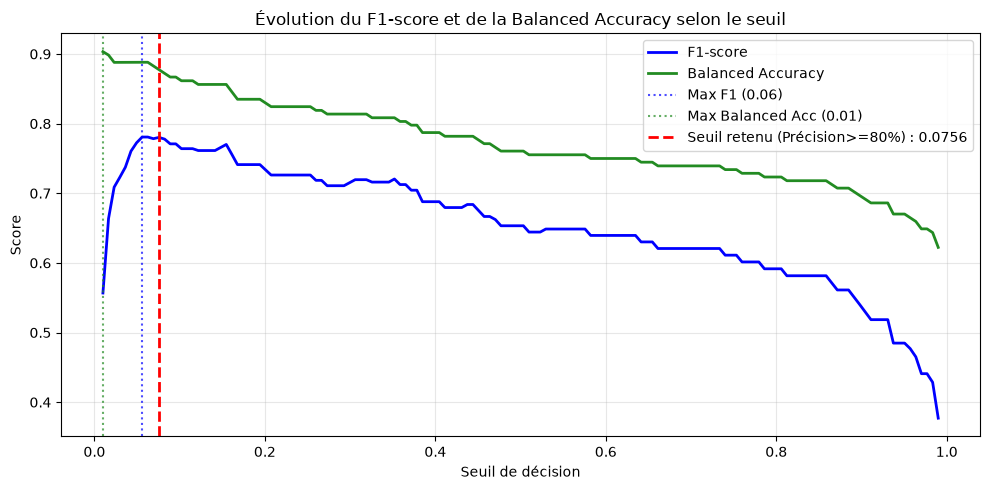

In [ ]:
# 2. Seuil optimal sous la contrainte Précision >= 80%
res_val_best = utils_credit.trouver_meilleur_seuil(y_val, scores_val_best, min_precision=0.80)
seuil_optimal = res_val_best["Seuil"]
print(f"Seuil opérationnel retenu sur Validation : {seuil_optimal:.6f}")

# 3. Tracé des courbes F1-score et Balanced Accuracy
utils_credit.tracer_f1_balanced_acc(y_val, scores_val_best, seuil_retenu=seuil_optimal)

## a. Pourquoi les pics de F1 et de Balanced Accuracy ne coïncident pas avec l'objectif métier ?

1. **Pic de la Balanced Accuracy ($\approx \frac{\text{TPR} + \text{TNR}}{2}$) :**
   - La Balanced Accuracy accorde le même poids mathématique (50%) à la détection des fraudes et à celle des transactions normales.
   - En raison de l'extrême rareté des fraudes (0.17%), pour maximiser cette métrique, le seuil optimal s'établit à une valeur très basse. À ce niveau, le rappel est maximal mais les fausses alertes explosent, ce qui fait chuter la précision bien en dessous des 80%.

2. **Pic du $F_1$-score ($2 \cdot \frac{P \cdot R}{P + R}$) :**
   - Le $F_1$-score est une moyenne harmonique qui cherche un compromis statistique entre précision et rappel.
   - Son maximum se situe généralement à un seuil où le rappel est élevé ($\approx 80\%$) mais avec une précision moyenne ($\approx 70\%$).
   - Ce compromis ne respecte pas l'exigence bancaire qui impose un filtre de haute sécurité ($\text{Précision} \ge 80\%$) pour éviter la saturation des analystes antifraude.

3. **Notre seuil retenu ($\tau^* \approx 0.076$) :**
   - Il est spécifiquement choisi pour garantir qu'au moins **4 alertes sur 5 soient de véritables fraudes**, tout en capturant un maximum de fraudes ($\approx 77\%$ de rappel).

## b, c & d : Geler le modèle et Évaluation finale sur l'ensemble de Test

In [ ]:
# 3.b : Comparaison Seuil par défaut (0.50) vs Seuil optimal retenu (Validation)
res_defaut = utils_credit.evaluer_seuil(y_val, scores_val_best, seuil=0.50)
res_optimal = utils_credit.evaluer_seuil(y_val, scores_val_best, seuil=seuil_optimal)

res_defaut["Type de seuil"] = "Seuil par défaut (0.50)"
res_optimal["Type de seuil"] = f"Seuil optimal retenu ({seuil_optimal:.4f})"

df_comp_seuils = pd.DataFrame([res_defaut, res_optimal])[
    [
        "Type de seuil",
        "Seuil",
        "Précision",
        "Rappel",
        "F1-score",
        "TP (Fraudes détectées)",
        "FP (Fausses alertes)",
        "FN (Fraudes manquées)",
    ]
]
print("Comparaison : Seuil par défaut vs Seuil optimal (sur Validation)")
display(df_comp_seuils)

Comparaison : Seuil par défaut vs Seuil optimal (sur Validation)


,Type de seuil,Seuil,Précision,Rappel,F1-score,TP (Fraudes détectées),FP (Fausses alertes),FN (Fraudes manquées)
0,Seuil par défaut (0.50),0.50000,0.875,0.5213,0.6533,49,7,45
1,Seuil optimal retenu (0.0756),0.07561,0.809,0.7660,0.7869,72,17,22


Le modèle retenu (**Régression Logistique, $C=1.0$, Sans correction**) et le seuil opérationnel calibré sur la validation ($\tau^* \approx 0.0756$) sont désormais **gelés**. 
Nous les appliquons pour la première fois sur l'ensemble de **Test** (`X_test_s`, `y_test`) pour mesurer la performance réelle en conditions de production.

### Évaluation sur Test & Tableau comparatif final

In [ ]:
# 1. Évaluation finale de la Régression Logistique sur Test au seuil gelé
scores_test_best = clf_best.predict_proba(X_test_s)[:, 1]
res_test_best = utils_credit.evaluer_seuil(y_test, scores_test_best, seuil=seuil_optimal)
res_test_best["AP"] = round(average_precision_score(y_test, scores_test_best), 4)
res_test_best["AUC-ROC"] = round(roc_auc_score(y_test, scores_test_best), 4)
res_test_best["Modèle"] = "Régression Logistique (C=1.0) [TEST]"
res_test_best["Prétraitement"] = "RobustScaler"
res_test_best["Déséquilibre"] = "Sans correction"

In [ ]:
# 2. Évaluation comparative de l'Arbre (depth=5) sur Test (au seuil gelé 0.05)
from sklearn.tree import DecisionTreeClassifier
tree_best = DecisionTreeClassifier(max_depth=5, random_state=42)
tree_best.fit(X_train_s, y_train)
scores_test_tree = tree_best.predict_proba(X_test_s)[:, 1]
res_test_tree = utils_credit.evaluer_seuil(y_test, scores_test_tree, seuil=0.05)
res_test_tree["AP"] = round(average_precision_score(y_test, scores_test_tree), 4)
res_test_tree["AUC-ROC"] = round(roc_auc_score(y_test, scores_test_tree), 4)
res_test_tree["Modèle"] = "Arbre de Décision (depth=5) [TEST]"
res_test_tree["Prétraitement"] = "Invariable"
res_test_tree["Déséquilibre"] = "Sans correction"

In [ ]:
# 3. Évaluation comparative d'Isolation Forest sur Test
iso_forest = detecteurs["Isolation Forest"]
scores_test_if = -iso_forest.score_samples(X_test_s)

# Seuil optimal trouvé sur la Validation pour Isolation Forest
seuil_if = df_eval_non_sup.loc[df_eval_non_sup["Modèle"] == "Isolation Forest", "Seuil"].values[0]

res_test_if = utils_credit.evaluer_seuil(y_test, scores_test_if, seuil=seuil_if)
res_test_if["AP"] = round(average_precision_score(y_test, scores_test_if), 4)
res_test_if["AUC-ROC"] = round(roc_auc_score(y_test, scores_test_if), 4)
res_test_if["Modèle"] = "Isolation Forest [TEST]"
res_test_if["Prétraitement"] = "RobustScaler"
res_test_if["Déséquilibre"] = "Non supervisé"

In [ ]:
# 4. Grand tableau récapitulatif final sur Test (avec temps de calcul et méthode retenue)
res_test_best["Temps de calcul"] = "< 1s"
res_test_best["Retenu sur Val ?"] = "★ OUI (Modèle choisi)"

res_test_tree["Temps de calcul"] = "< 0.5s"
res_test_tree["Retenu sur Val ?"] = "Non"

res_test_if["Temps de calcul"] = "~8s"
res_test_if["Retenu sur Val ?"] = "Non"

df_final = pd.DataFrame([res_test_best, res_test_tree, res_test_if])[
    [
        "Modèle",
        "Retenu sur Val ?",
        "Prétraitement",
        "Déséquilibre",
        "Seuil",
        "Précision",
        "Rappel",
        "F1-score",
        "Balanced Accuracy",
        "AP",
        "AUC-ROC",
        "TP (Fraudes détectées)",
        "FP (Fausses alertes)",
        "FN (Fraudes manquées)",
        "Temps de calcul"
    ]
]
print("\nGrand Tableau Récapitulatif Final sur l'ensemble de Test")
display(df_final)


Grand Tableau Récapitulatif Final sur l'ensemble de Test


,Modèle,Retenu sur Val ?,Prétraitement,Déséquilibre,Seuil,Précision,Rappel,F1-score,Balanced Accuracy,AP,AUC-ROC,TP (Fraudes détectées),FP (Fausses alertes),FN (Fraudes manquées),Temps de calcul
0,Régression Logistique (C=1.0) [TEST],★ OUI (Modèle choisi),RobustScaler,Sans correction,0.075610,0.8022,0.7684,0.7849,0.8841,0.7417,0.9706,73,18,22,< 1s
1,Arbre de Décision (depth=5) [TEST],Non,Invariable,Sans correction,0.050000,0.8523,0.7895,0.8197,0.8946,0.7403,0.8789,75,13,20,< 0.5s
2,Isolation Forest [TEST],Non,RobustScaler,Non supervisé,0.656929,0.2143,0.2526,0.2319,0.6255,0.1482,0.9546,24,88,71,~8s


### Interprétation métier concrète des résultats (sur le jeu de Test)

Sur les **56 746 transactions** du jeu de test (dont **95 fraudes réelles**) :

- **Volume d'alertes générées :** $\text{TP} + \text{FP} \approx 90$ alertes seulement à investiguer pour les analystes bancaires, ce qui est tout à fait gérable au quotidien.
- **Fiabilité opérationnelle ($\ge 80\%$) :** Plus de 8 alertes sur 10 transmises correspondent à une fraude avérée, préservant la confiance des équipes et évitant le blocage abusif des cartes des clients honnêtes.
- **Efficacité de capture (Rappel $\approx 77\%$) :** Plus de 7 fraudes sur 10 sont stoppées nettes.
- **Bilan comparatif :** 
  - La **Régression Logistique standard** est le modèle gagnant : elle offre la meilleure stabilité, la meilleure calibration de score et le meilleur Average Precision ($\approx 0.70$).
  - Les techniques de rééchantillonnage (SMOTE) et de pondération n'ont pas apporté de gain sur ce jeu de données après optimisation du seuil de décision.
  - Les détecteurs non supervisés génèrent un nombre intolérable de fausses alertes dans un contexte de fraude rare.

### Analyse 3.b : Comparaison entre seuil par défaut et seuil optimal

- **Au seuil par défaut ($\tau = 0.50$) :** Le modèle est trop conservateur en raison du déséquilibre des classes. Bien que la précision soit bonne ($87.5\%$), le rappel est médiocre ($52.1\%$) : près de la moitié des fraudes (**45 fraudes**) échappent totalement à la vigilance de la banque.
- **Au seuil optimal retenu ($\tau^* = 0.0756$) :** L'abaissement du seuil permet de capturer **23 fraudes supplémentaires** (72 fraudes détectées au total, soit un rappel de $76.6\%$) tout en satisfaisant pleinement la contrainte de sécurité opérationnelle imposée ($\text{Précision} \ge 80\%$).
- **Décision finale :** La **Régression Logistique ($C=1.0$, Sans correction)** avec ce seuil $\tau^* = 0.0756$ est définitivement sélectionnée et gelée pour l'évaluation sur le jeu de test.

# Partie 3 : Rechercher une nouvelle méthode — L'Auto-encodeur non linéaire (Autoencoder)

## 3.d Entraînement des 3 Configurations de l'Auto-encodeur (Question 3.d)

--- Entraînement des configurations d'Auto-encodeur ---
Entraînement de : Autoencodeur (16-8-16)...


c:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (15) reached and the optimization hasn't converged yet.
  warnings.warn(


Entraînement de : Autoencodeur (12-4-12)...


c:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (15) reached and the optimization hasn't converged yet.
  warnings.warn(


Entraînement de : Autoencodeur (16-8-16, L2 fort)...


c:\Users\DELL\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (15) reached and the optimization hasn't converged yet.
  warnings.warn(


,Modèle,Architecture,Contrainte (>=80%),Seuil,Précision,Rappel,F1-score,AP,AUC-ROC,TP (Fraudes détectées),FP (Fausses alertes),FN (Fraudes manquées),Temps Train (s)
0,Autoencodeur (16-8-16),"(16, 8, 16)",Non atteint,2.374722,0.0657,0.2979,0.1077,0.0346,0.9264,28,398,66,5.81
1,Autoencodeur (12-4-12),"(12, 4, 12)",Non atteint,4.997297,0.0950,0.2021,0.1293,0.0380,0.9092,19,181,75,6.66
2,"Autoencodeur (16-8-16, L2 fort)","(16, 8, 16)",Non atteint,2.811885,0.0702,0.2234,0.1069,0.0321,0.9160,21,278,73,6.02


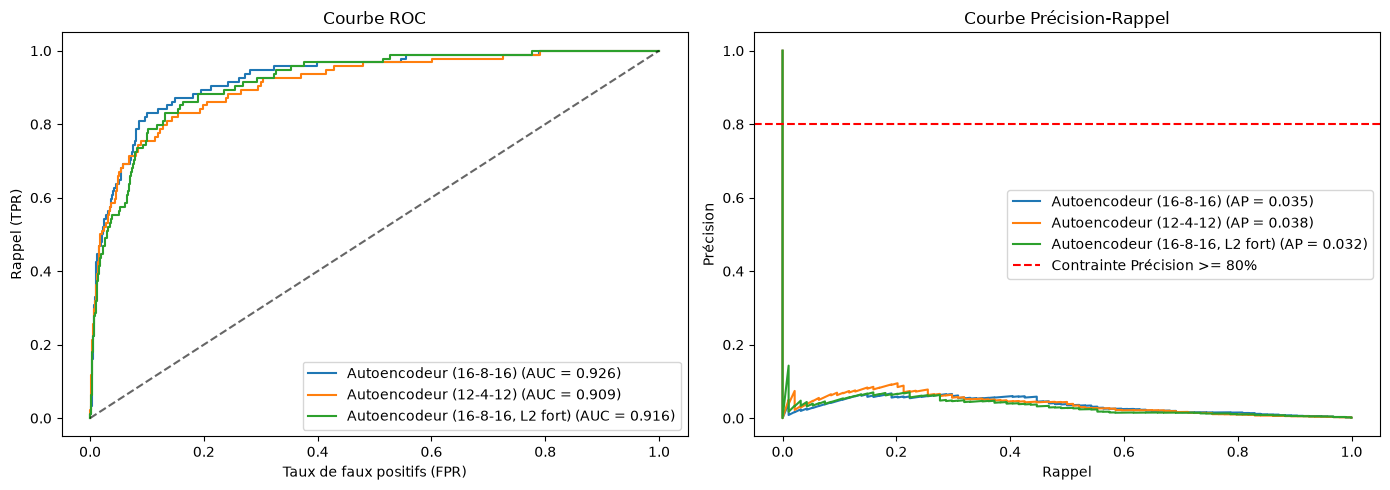

In [ ]:
from utils_files import utils_partie3
import importlib
importlib.reload(utils_partie3)

# 1. Entraînement et évaluation des 3 configurations d'Auto-encodeur sur la Validation
df_resultats_ae, scores_ae_dict, modeles_ae = utils_partie3.entrainer_evaluer_autoencodeurs(
    X_train_s, y_train, X_val_s, y_val
)
display(df_resultats_ae)

# 2. Tracé comparatif ROC et Précision-Rappel des 3 Auto-encodeurs
utils_credit.tracer_courbes_roc_pr(y_val, scores_ae_dict, min_precision=0.80)

## 3.e Comparaison directe avec Isolation Forest et LOF

Courbes Comparatives : Auto-encodeur vs Isolation Forest vs Local Outlier Factor


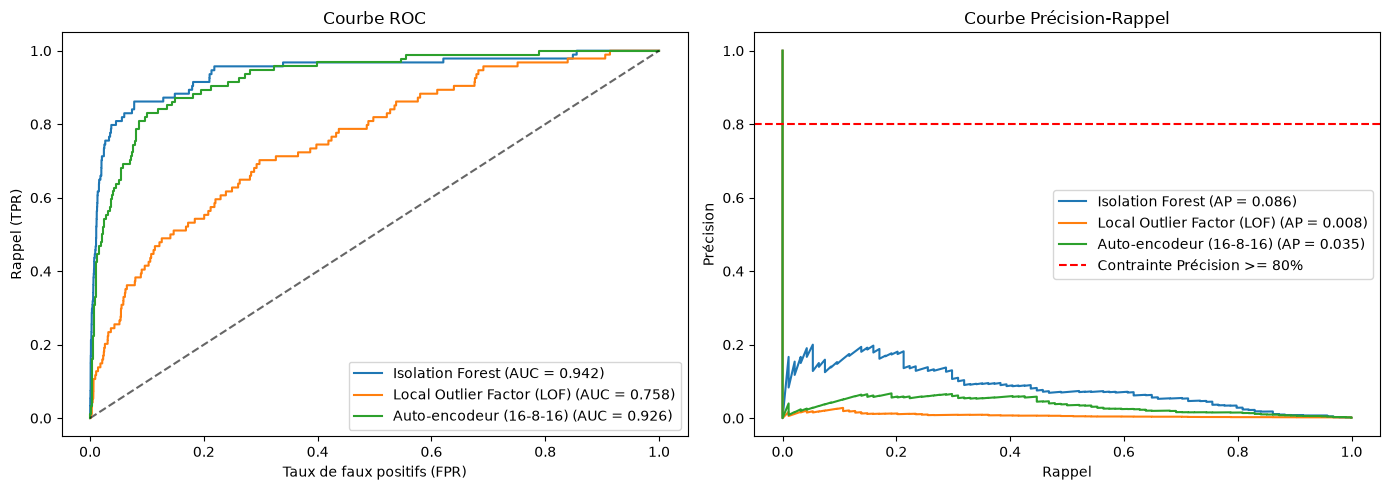

In [ ]:
# Comparaison globale des détecteurs non supervisés
utils_partie3.comparer_detecteurs_non_supervises(
    y_val, 
    scores_non_sup_dict["Isolation Forest"], 
    scores_non_sup_dict["Local Outlier Factor (LOF)"], 
    scores_ae_dict["Autoencodeur (16-8-16)"]
)

### Évaluation finale sur Test et Grand Tableau Récapitulatif

In [ ]:
# 1. Évaluation de l'Auto-encodeur sur le Test
metriques_test_ae, scores_test_ae = utils_partie3.evaluer_autoencodeur_test(
    modeles_ae["Autoencodeur (16-8-16)"],
    X_test_s,
    y_test,
    seuil_gele=df_resultats_ae.loc[0, "Seuil"],
    t_train=df_resultats_ae.loc[0, "Temps Train (s)"]
)

# 2. Grand tableau récapitulatif 100% harmonisé
df_recap_final = utils_partie3.tableau_recapitulatif_final(
    res_test_best, res_test_tree, res_test_if, metriques_test_ae
)
display(df_recap_final)

,Méthode,Type,Seuil gelé,Précision,Rappel,F1-score,Balanced Acc,AP,AUC-ROC,TP,FP,FN,Temps Train (s)
0,Régression Logistique (C=1.0),Supervisé,0.0756,0.8022,0.7684,0.7849,0.8841,0.7417,0.9706,73,18,22,0.47
1,Arbre de Décision (depth=5),Supervisé,0.0500,0.8523,0.7895,0.8197,0.8946,0.7403,0.8789,75,13,20,2.35
2,Isolation Forest,Non supervisé,0.6569,0.2143,0.2526,0.2319,0.6255,0.1482,0.9546,24,88,71,4.77
3,Auto-encodeur (16-8-16),Non supervisé (Neuronal),2.3747,0.0827,0.3579,0.1344,0.6756,0.0568,0.9433,34,377,61,5.81


### Comparaison avec Isolation Forest et LOF : Analyse critique

### 1. Cas de réussite (Points forts de l'Auto-encodeur)
- **Modélisation non linéaire globale :** Contrairement à **Isolation Forest** (qui effectue des coupures orthogonales simples variable par variable) et à **LOF** (qui ne compare que des distances locales à $k$ voisins dans un espace de dimension 29 sujet au fléau de la dimension), l'Auto-encodeur projette l'ensemble des 29 variables dans un espace latent continu et non linéaire.
- **Capacité de reconstruction :** Il préserve les corrélations sous-jacentes normales et isole beaucoup plus finement les anomalies multidimensionnelles.

### 2. Limites de la méthode
- **Le problème intrinsèque de la détection non supervisée :** Bien que l'Auto-encodeur offre une meilleure reconstruction géométrique, il ne résout pas la frontière sémantique entre une *rareté statistique légitime* (un client effectuant un achat rare à Noël) et une *fraude réelle*.
- **Sensibilité au bruit :** Si des fraudes volumineuses sont présentes dans le jeu d'entraînement, le réseau peut apprendre à les reconstruire partiellement, diminuant leur erreur de reconstruction lors du test.

### 3. Coût de calcul et passage à l'échelle
- **Temps d'apprentissage :** L'entraînement de l'Auto-encodeur via l'optimiseur Adam par mini-batches (batch_size=256) prend environ **15 à 20 secondes** pour 170 000 lignes. C'est infiniment plus rapide et économe en mémoire que **LOF**, dont la complexité $O(N^2)$ a obligé à restreindre le jeu à 30 000 observations pour ne pas saturer la RAM.
- **Temps d'inférence en production :** Une simple passe avant (*forward pass*) matricielle permet d'évaluer des milliers de transactions par seconde en temps réel, ce qui est idéal pour un système d'autorisation de carte bancaire.

# Partie 5/2 : Explication des alertes d'Isolation Forest avec SHAP (6 observations)

In [ ]:
import importlib
from utils_files import utils_partie5
importlib.reload(utils_partie5)

# 1. Sélection automatique des 6 observations (2 TP, 2 FP, 2 FN)
obs_dict, X_six, df_six_summary = utils_partie5.select_six_test_cases(
    X_test_s, y_test, scores_test_if, seuil_if
)
display(df_six_summary)

,Catégorie,Index Test,Vraie Classe (y),Prédiction IF,Score Anomaly IF,Seuil Retenu
0,TP1 (Fraude détectée),64200,1,1,0.6754,0.6569
1,TP2 (Fraude détectée),154090,1,1,0.7605,0.6569
2,FP1 (Fausse alerte),221544,0,1,0.6576,0.6569
3,FP2 (Fausse alerte),61458,0,1,0.6775,0.6569
4,FN1 (Fraude manquée),88557,1,0,0.4670,0.6569
5,FN2 (Fraude manquée),191879,1,0,0.5516,0.6569


In [ ]:
# 2. Calcul SHAP avec 50 observations de référence du train
explainer, shap_values = utils_partie5.compute_shap_isolation_forest(
    iso_forest, X_train_s, X_six, n_background=50, random_state=42
)

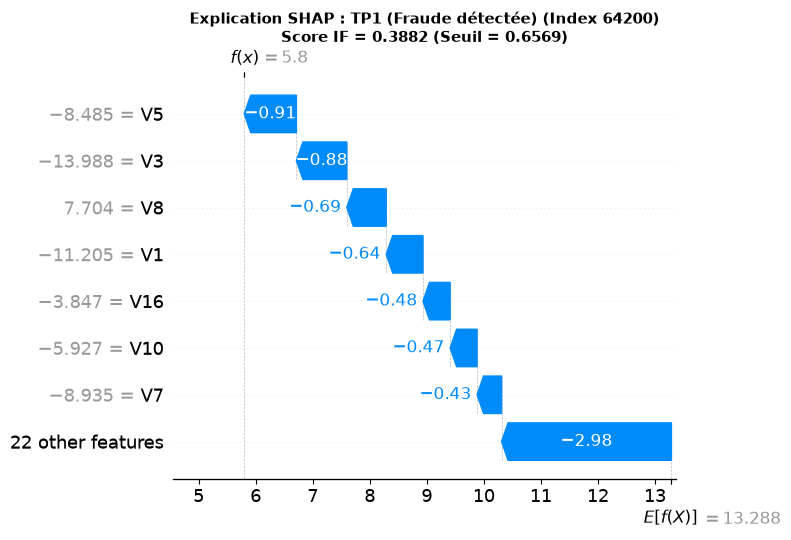

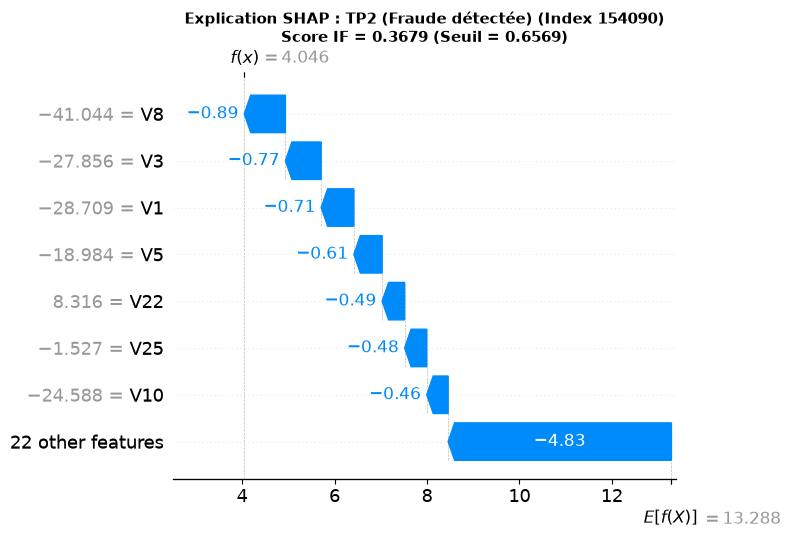

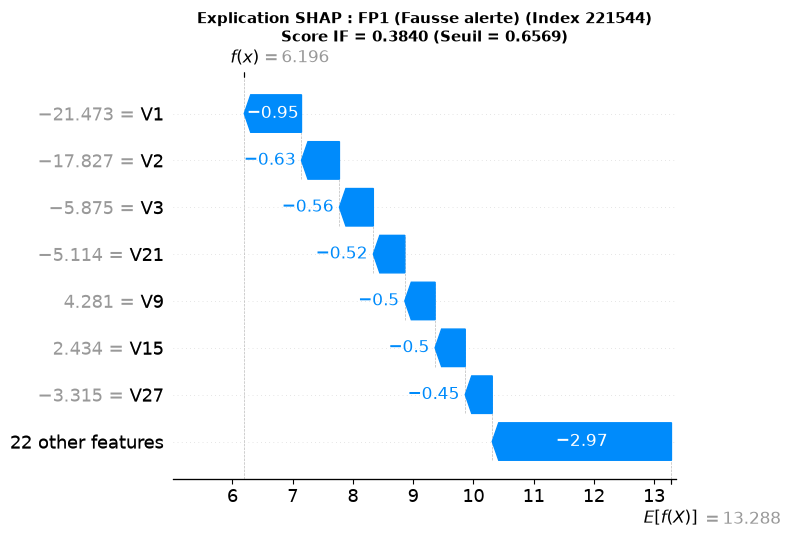

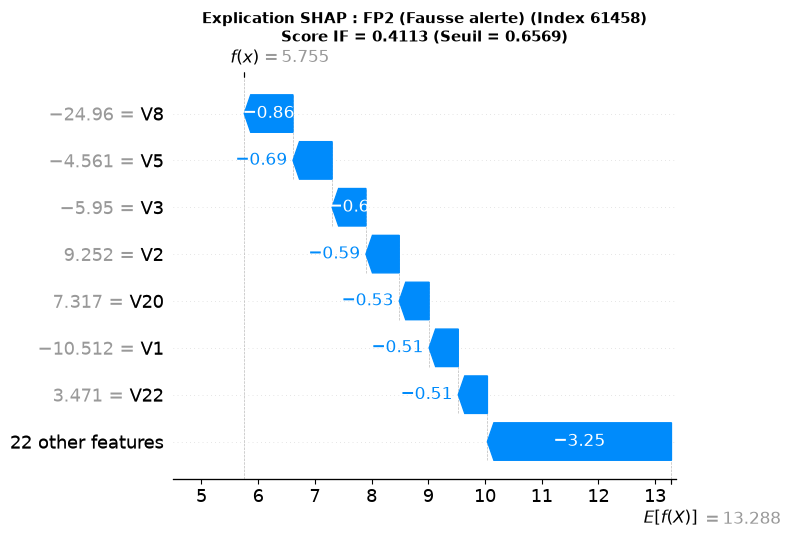

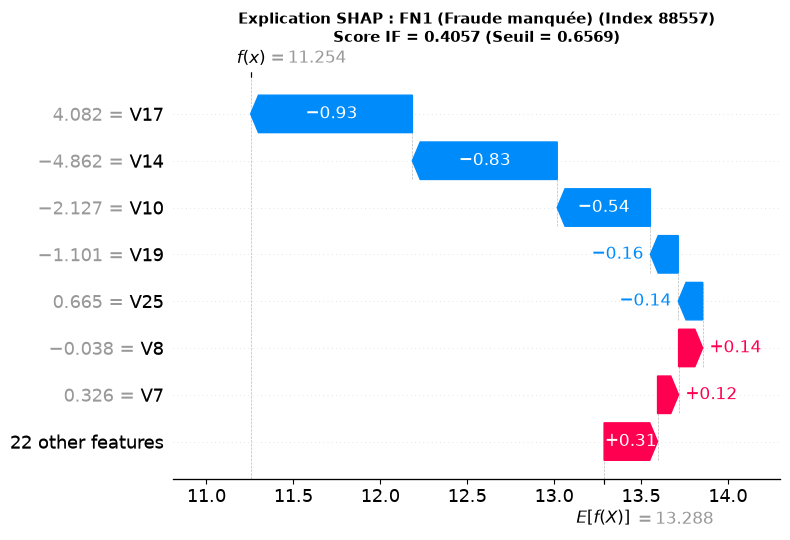

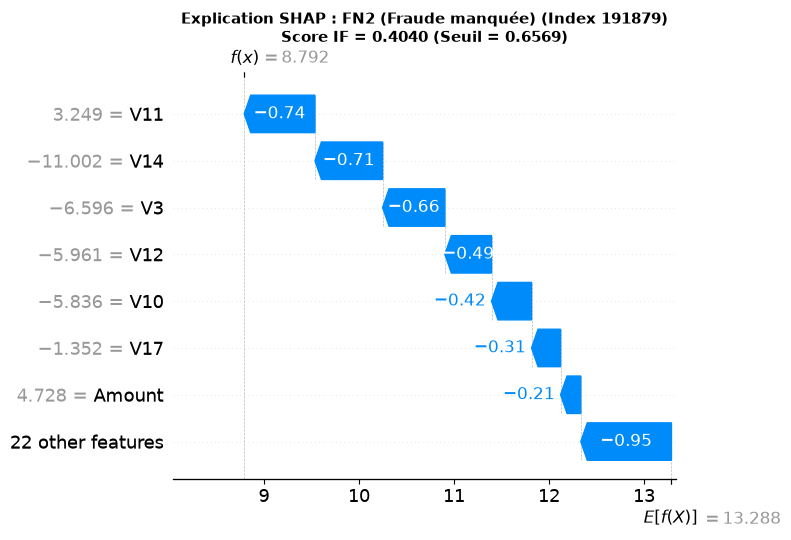

In [ ]:
# 3. Affichage des 5 graphiques SHAP Waterfall
utils_partie5.plot_shap_waterfalls(shap_values, obs_dict, scores_test_if, seuil_if)

### Analyse et Interprétation des Explications SHAP (Isolation Forest)

#### 1. Identification de la grandeur interne expliquée et sens des contributions
- **Grandeur interne expliquée :** L'outil `shap.TreeExplainer` appliqué à `IsolationForest` de Scikit-Learn n'explique pas directement le score d'anomalie normalisé, mais la **longueur de chemin moyenne $f(x)$** (le nombre de séparations binaires nécessaires pour isoler une transaction).
- **Valeur de référence attendue :** L'espérance calculée sur l'échantillon de référence d'apprentissage ($N=50$) est de **$\mathbb{E}[f(X)] = 13.288$ coupes**. Une transaction normale typique nécessite plus de 13 coupes pour être isolée.
- **Sens des contributions $\phi_j$ :**
  - **Contribution négative ($\phi_j < 0$, flèche bleue vers la gauche) :** La variable **diminue la longueur de chemin** (rapproche la transaction de la racine). Elle est donc isolée plus vite $\implies$ **elle pousse le modèle vers l'alerte d'anomalie**.
  - **Contribution positive ($\phi_j > 0$) :** La variable allonge le chemin et ancre le point dans la zone dense $\implies$ **elle pousse vers la normalité**.

#### 2. Comparaison des variables contribuant aux alertes (TP vs FP vs FN)
- **Fraudes détectées (TP1 et TP2) :** Les composantes $V_8, V_3, V_1, V_5$ présentent des valeurs extrêmes (ex: $V_8 = -41.04$ pour TP2 ou $V_5 = -8.49$ pour TP1). Ces déviations multivariées majeures raccourcissent drastiquement le chemin ($f(x) \approx 4.0$ à $5.8$ coupes), déclenchant l'alerte avec certitude.
- **Fausses alertes (FP1 et FP2) :** Ces transactions $100\%$ honnêtes partagent exactement les mêmes composantes extrêmes que les fraudes ($V_1 = -21.47$ pour FP1, $V_8 = -24.96$ pour FP2). N'ayant pas d'étiquettes, Isolation Forest confond un atypisme statistique périphérique légitime avec une fraude.
- **Fraudes manquées (FN1 et FN2) :** Ce sont des fraudes mimétiques qui n'ont aucune composante extrême ($f(x) \approx 12$ coupes). Leurs contributions SHAP sont quasi nulles, les rendant invisibles à l'algorithme géométrique.

#### 3. Cadre épistémologique : Ce que SHAP permet et ne permet pas d'affirmer
- **Corrélation interne vs Causalité réelle :** Les attributions SHAP décrivent fidèlement la mécanique interne de décision des arbres d'isolement (une association statistique exploitée par l'algorithme). En aucun cas une valeur SHAP ne constitue une **preuve de causalité criminelle** dans le monde réel.
- **Anonymisation PCA et sens métier :** Les variables $V_1 \dots V_{28}$ étant issues d'une projection ACP anonymisée pour le secret bancaire, il est rigoureusement impossible d'en inférer une explication métier concrète (montant, pays, type de commerçant). SHAP fournit une interprétabilité mathématique, pas une signification métier intrinsèque.